--- Step 0: Loading and Preprocessing Data ---
Data split successfully. Train size: 21113, Test size: 9049

--- Part 1: Build & Compare ---
Linear Regression Median Predicted Value: 0.2283
Confusion Matrix between Model A and Model B classifications:
               Model B: Low  Model B: High
Model A: Low           4524              0
Model A: High          2694           1831
Mismatched Cases: 2694 individuals (29.77% of test set)

--- Part 2.1: Simpson's Paradox Hunt ---
Coefficient for 'hours-per-week' in Full Test Set: 0.5785
Coefficient for 'hours-per-week' in Male Subgroup: 0.5178
Coefficient for 'hours-per-week' in Female Subgroup: 0.3884

--- Part 2.2: Omitted-Variable Bias ---
Predictor                           | Full Model Coef | Reduced Model Coef | % Change  
----------------------------------------------------------------------------------------
age                                 | 0.3280          | 0.3254             | -0.77     %
capital-gain                        | 0

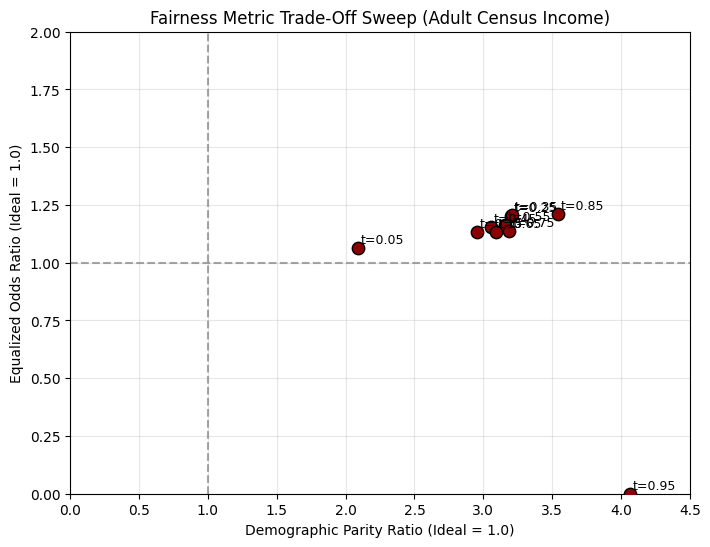

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
# ==========================================
# 0. DATA LOADING & PREPROCESSING
# ==========================================
print("--- Step 0: Loading and Preprocessing Data ---")

# URL for the adult dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income"
]

# Read dataset, safely skipping any inconsistent metadata/lines
df = pd.read_csv(url, names=columns, sep=',', skipinitialspace=True, na_values='?', on_bad_lines='skip')

# 1. Handling Missing Values: Drop rows with missing values
df = df.dropna()

# 2. Target Variable Encoding: 1 if >50K, 0 if <=50K
df['target'] = (df['income'] == '>50K').astype(int)

# Save demographic copies for stress tests before dummy encoding
df_demographics = df[['sex', 'race', 'age']].copy()


# 3. Outlier Mitigation: Cap extreme capital gains/losses at 99th percentile
cap_gain = df['capital-gain'].quantile(0.99)
cap_loss = df['capital-loss'].quantile(0.99)
df['capital-gain'] = np.clip(df['capital-gain'], 0, cap_gain)
df['capital-loss'] = np.clip(df['capital-loss'], 0, cap_loss)

# 4. Categorical Encoding: One-hot encode features
categorical_cols = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Select features and target
X = df_encoded.drop(columns=['income', 'target', 'fnlwgt']) # Drop fnlwgt as it's a survey weight
y = df_encoded['target']

# 5. Train-Test Split (70/30, random_state=359 based on roll number)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=359)

# 6. Feature Scaling: Standardize numerical columns
num_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"Data split successfully. Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}\n")

# ==========================================
# PART 1 — BUILD & COMPARE
# ==========================================
print("--- Part 1: Build & Compare ---")

# Model A: Linear Regression (OLS Probability)
model_a = LinearRegression()
model_a.fit(X_train_scaled, y_train)
pred_a_raw = model_a.predict(X_test_scaled)

# Threshold Model A predictions at the median
median_pred_a = np.median(pred_a_raw)
clf_a = (pred_a_raw >= median_pred_a).astype(int)

# Model B: Logistic Regression
model_b = LogisticRegression(max_iter=1000, random_state=359)
model_b.fit(X_train_scaled, y_train)
pred_b_prob = model_b.predict_proba(X_test_scaled)[:, 1]

# Threshold Model B predictions at 0.5
clf_b = (pred_b_prob >= 0.5).astype(int)

# Mismatch Evaluation
cm = confusion_matrix(clf_a, clf_b)
mismatched = np.sum(clf_a != clf_b)
pct_mismatched = (mismatched / len(y_test)) * 100

print(f"Linear Regression Median Predicted Value: {median_pred_a:.4f}")
print("Confusion Matrix between Model A and Model B classifications:")
print(pd.DataFrame(cm, index=['Model A: Low', 'Model A: High'], columns=['Model B: Low', 'Model B: High']))
print(f"Mismatched Cases: {mismatched} individuals ({pct_mismatched:.2f}% of test set)\n")


# ==========================================
# PART 2.1 — SIMPSON'S PARADOX HUNT
# ==========================================
print("--- Part 2.1: Simpson's Paradox Hunt ---")
# Let's observe the effect of 'hours-per-week' across demographic subgroups (e.g., sex)
# Re-aligning subgroups based on the unscaled split index
test_indices = X_test.index
sex_test = df_demographics.loc[test_indices, 'sex']

# Fit full logistic model on test elements or subsets to observe direct coefficient changes
# Using 'hours-per-week' as the key predictor
predictor_col = 'hours-per-week'

model_full = LogisticRegression(max_iter=1000).fit(X_test_scaled[[predictor_col]], y_test)
coef_full = model_full.coef_[0][0]

mask_male = (sex_test == 'Male')
mask_female = (sex_test == 'Female')

model_male = LogisticRegression(max_iter=1000).fit(X_test_scaled.loc[mask_male, [predictor_col]], y_test[mask_male])
coef_male = model_male.coef_[0][0]

model_female = LogisticRegression(max_iter=1000).fit(X_test_scaled.loc[mask_female, [predictor_col]], y_test[mask_female])
coef_female = model_female.coef_[0][0]

print(f"Coefficient for '{predictor_col}' in Full Test Set: {coef_full:.4f}")
print(f"Coefficient for '{predictor_col}' in Male Subgroup: {coef_male:.4f}")
print(f"Coefficient for '{predictor_col}' in Female Subgroup: {coef_female:.4f}\n")


# ==========================================
# PART 2.2 — OMITTED-VARIABLE BIAS
# ==========================================
print("--- Part 2.2: Omitted-Variable Bias ---")
# Confounder to drop: 'education-num' (highly correlated with income)
confounder = 'education-num'

# Full Model (all features)
model_ovb_full = LogisticRegression(max_iter=1000, random_state=359).fit(X_train_scaled, y_train)

# Reduced Model (without education-num)
X_train_reduced = X_train_scaled.drop(columns=[confounder])
model_ovb_reduced = LogisticRegression(max_iter=1000, random_state=359).fit(X_train_reduced, y_train)

# Select 4 representative predictors to report shifts
predictors_to_track = ['age', 'capital-gain', 'hours-per-week', 'marital-status_Married-civ-spouse']

print(f"{'Predictor':<35} | {'Full Model Coef':<15} | {'Reduced Model Coef':<18} | {'% Change':<10}")
print("-" * 88)
for pred in predictors_to_track:
    idx_full = X_train_scaled.columns.get_loc(pred)
    idx_red = X_train_reduced.columns.get_loc(pred)

    c_full = model_ovb_full.coef_[0][idx_full]
    c_red = model_ovb_reduced.coef_[0][idx_red]
    pct_chg = ((c_red - c_full) / c_full) * 100
    print(f"{pred:<35} | {c_full:<15.4f} | {c_red:<18.4f} | {pct_chg:<10.2f}%")
print()


# ==========================================
# PART 2.3 — ADVERSARIAL SUBSET CONSTRUCTION
# ==========================================
print("--- Part 2.3: Adversarial Subset Construction ---")
# High confidence errors
false_pos_mask = (pred_b_prob >= 0.75) & (y_test == 0)
false_neg_mask = (pred_b_prob <= 0.25) & (y_test == 1)
adversarial_mask = false_pos_mask | false_neg_mask

adv_indices = y_test[adversarial_mask].index
total_adv_count = len(adv_indices)
pct_adv = (total_adv_count / len(y_test)) * 100

print(f"Total High-Confidence Wrong Predictions: {total_adv_count} ({pct_adv:.2f}% of test set)")

# Sample up to 50 rows
np.random.seed(359)
sample_size = min(50, total_adv_count)
sampled_indices = np.random.choice(adv_indices, size=sample_size, replace=False)

# Analyze characteristics of the subset
adv_sample_df = df.loc[sampled_indices]
full_test_df = df.loc[test_indices]

print(f"\nDemographic Baseline Comparison (Sampled 50 Adversarial Rows vs Full Test Set):")
print(f"Adversarial Mean Age: {adv_sample_df['age'].mean():.1f} vs Full Test Mean Age: {full_test_df['age'].mean():.1f}")
print(f"Adversarial Pct Male: {(adv_sample_df['sex'] == 'Male').mean()*100:.1f}% vs Full Test Pct Male: {(full_test_df['sex'] == 'Male').mean()*100:.1f}%")

# Finding a dominant common characteristic
avg_hours_adv = adv_sample_df['hours-per-week'].mean()
pct_married_adv = (adv_sample_df['marital-status'] == 'Married-civ-spouse').mean() * 100
print(f"Common Characteristic: {pct_married_adv:.1f}% of adversarial instances have status 'Married-civ-spouse'.\n")


# ==========================================
# PART 2.4 — FAIRNESS TRADE-OFF ANALYSIS
# ==========================================
print("--- Part 2.4: Fairness Trade-Off Analysis ---")
# Group A = Male, Group B = Female
group_a_mask = (sex_test == 'Male').values
group_b_mask = (sex_test == 'Female').values

thresholds = np.arange(0.05, 0.96, 0.1)
fairness_data = []

for t in thresholds:
    y_pred_t = (pred_b_prob >= t).astype(int)

    # Selection Rates for Demographic Parity
    sr_a = np.mean(y_pred_t[group_a_mask] == 1)
    sr_b = np.mean(y_pred_t[group_b_mask] == 1)
    dp = sr_a / sr_b if sr_b > 0 else 0

    # True Positive & False Positive Rates for Equalized Odds
    y_test_a = y_test[group_a_mask].values
    y_test_b = y_test[group_b_mask].values
    y_pred_a = y_pred_t[group_a_mask]
    y_pred_b = y_pred_t[group_b_mask]

    tpr_a = np.sum((y_pred_a == 1) & (y_test_a == 1)) / np.sum(y_test_a == 1) if np.sum(y_test_a == 1) > 0 else 0
    tpr_b = np.sum((y_pred_b == 1) & (y_test_b == 1)) / np.sum(y_test_b == 1) if np.sum(y_test_b == 1) > 0 else 0
    fpr_a = np.sum((y_pred_a == 1) & (y_test_a == 0)) / np.sum(y_test_a == 0) if np.sum(y_test_a == 0) > 0 else 0
    fpr_b = np.sum((y_pred_b == 1) & (y_test_b == 0)) / np.sum(y_test_b == 0) if np.sum(y_test_b == 0) > 0 else 0

    eo_tpr = tpr_a / tpr_b if tpr_b > 0 else 0
    eo_fpr = fpr_a / fpr_b if fpr_b > 0 else 0
    eo = min(eo_tpr, eo_fpr)

    # Predictive Parity
    pp_a = np.sum((y_test_a == 1) & (y_pred_a == 1)) / np.sum(y_pred_a == 1) if np.sum(y_pred_a == 1) > 0 else 0
    pp_b = np.sum((y_test_b == 1) & (y_pred_b == 1)) / np.sum(y_pred_b == 1) if np.sum(y_pred_b == 1) > 0 else 0
    pp = pp_a / pp_b if pp_b > 0 else 0

    fairness_data.append({'Threshold': t, 'DP': dp, 'EO': eo, 'PP': pp})

fairness_df = pd.DataFrame(fairness_data)
print(fairness_df.to_string(index=False))
# Plotting the Trade-Off Chart
plt.figure(figsize=(8, 6))
plt.scatter(fairness_df['DP'], fairness_df['EO'], color='darkred', edgecolors='black', s=80, zorder=3)
for i, row in fairness_df.iterrows():
    plt.text(row['DP'] + 0.02, row['EO'] + 0.02, f"t={row['Threshold']:.2f}", fontsize=9)
plt.title("Fairness Metric Trade-Off Sweep (Adult Census Income)")
plt.xlabel("Demographic Parity Ratio (Ideal = 1.0)")
plt.ylabel("Equalized Odds Ratio (Ideal = 1.0)")
plt.axvline(1.0, color='gray', linestyle='--', alpha=0.7)
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.7)
plt.xlim(0, 4.5) # DP can expand widely based on threshold imbalances
plt.ylim(0, 2.0)
plt.grid(True, alpha=0.3)
plt.show()